# 4 - Figure 3: Experiment 4 (task-irrelevant sounds)

Experiment 4 (`EX_5`): participants viewed the scenes while monaural sounds were presented, with
instructions to ignore them and no auditory responses. Drawn exactly as one panel of Figure 2
(`03_figures_2_4.ipynb`): a peri-saccadic line plot (congruent vs incongruent, mean ± SEM) on the
left, two amplitude × time heatmaps on the right (congruent on top, incongruent below, each marked
by a coloured spine), and one shared colorbar. Panel size, fonts, colours, y-limits, heatmap
binning and significance bars are Figure 2's.

Only the saccade count is drawn: there is no task, so there are no responses — no P(correct), no
RT, and no median-RT line or band.

**Input**   `data_preprocessed/EX_5/long_format_alt_all.csv`
**Output**  `summaries/plots/figure3.{png,pdf}`

Significance tests and heatmap matrices are cached to `summaries/cache/`; set
`LOAD_CACHE = False` in the cache cell to recompute after changing a parameter.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from pathlib import Path
import math
import os
import sys
import importlib
import pickle

sys.path.insert(0, 'src')

import peri_sac
import config
import src.analysis_heatmap as analysis_heatmap

importlib.reload(peri_sac)
importlib.reload(config)
importlib.reload(analysis_heatmap)

from peri_sac import (
    calculate_running_window_metrics,
    plot_single_condition,
    test_pairwise_conditions,
    test_condition_vs_baseline,
    calculate_baseline_metrics_from_trials,
    apply_fdr_correction,
    plot_significance_bars,
    DEFAULT_METRICS,
    COLOR_PALETTES,
)
from config import (
    prepare_alternative_data,
    build_filter,
    METRIC_COLUMN_MAP,
    AMPLITUDE_UNIT_LABEL,
)
from src.analysis_heatmap import prepare_amplitude_time_heatmap, plot_amplitude_time_heatmap

%matplotlib inline
plt.rcParams['figure.dpi'] = 300
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

## Configuration

In [2]:
# ====================================================================
# EXPERIMENT
# ====================================================================

EXPERIMENT       = 'EX_5'
EXPERIMENT_LABEL = 'Exp 4. monaural-none'

# ====================================================================
# TIME / WINDOW PARAMETERS  (identical to Figure 2)
# ====================================================================

SOUND_SELECTION  = 'both'
TIME_REFERENCE   = 'time_from_sound_to_sacc_start'
TIME_RANGE       = (-500, 1000)
WINDOW_SIZE      = 100
STEP_SIZE        = 25
BASELINE_RANGE   = (-500, 0)

METRIC = 'saccade_count_normalized'

# ====================================================================
# FIGURE CONFIGURATION  (identical to Figure 2 unless noted)
# ====================================================================

LINE_YLIM = (-42, 42)

# Figure 2's per-panel size; the canvas is 2x2 of these (see the plot cell)
CELL_W_V2    = 8.5
CELL_H_V2    = 4.1

LINE_W_RATIO = 2.5
HM_W_RATIO   = 1.3
CBAR_W_RATIO = 0.09

HM_SPINE_LW  = 2.5
FONTSIZE     = 12

LEGEND_LOC   = 'lower right'    # Figure 2 uses 'lower left' with (-0.015, -0.02)
LEGEND_POS   = (1.015, -0.02)   # bbox_to_anchor: corner of the legend box named by LEGEND_LOC
PANEL_LABEL  = None   # e.g. 'A' if the panel is combined with others

# Heatmap data parameters (changing any of these requires recomputing the cache)
HM_AMPLITUDE_COL      = METRIC_COLUMN_MAP['amplitude']
HM_AMPLITUDE_UNIT     = AMPLITUDE_UNIT_LABEL
HM_BINNING_METHOD     = 'quantile_presound'
HM_N_BINS             = 10
HM_PER_SUBJECT        = False
HM_PRESOUND_THRESHOLD = 0
HM_VLIM               = None
HM_TIME_REFERENCE     = TIME_REFERENCE
HM_TIME_RANGE         = TIME_RANGE
HM_BASELINE_RANGE     = BASELINE_RANGE
HM_WINDOW_SIZE        = WINDOW_SIZE * 2
HM_STEP_SIZE          = STEP_SIZE  * 2

OUTPUT_PATH = Path('summaries') / 'plots'
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

print(f'Experiment    : {EXPERIMENT}  ({EXPERIMENT_LABEL})')
print(f'Metric        : {METRIC}')
print(f'Time reference: {TIME_REFERENCE}')
print(f'Baseline range: {BASELINE_RANGE} ms')
print(f'HM bins       : {HM_N_BINS} ({HM_BINNING_METHOD})')
print(f'HM window     : {HM_WINDOW_SIZE} ms  step: {HM_STEP_SIZE} ms')

Experiment    : EX_5  (Exp 4. monaural-none)
Metric        : saccade_count_normalized
Time reference: time_from_sound_to_sacc_start
Baseline range: (-500, 0) ms
HM bins       : 10 (quantile_presound)
HM window     : 200 ms  step: 50 ms


## Load Data & Compute Running-Window Metrics

In [3]:
data_raw = pd.read_csv(
    os.path.join(f'data_preprocessed/{EXPERIMENT}', 'long_format_alt_all.csv'),
    low_memory=False,
)
print(f'Rows: {len(data_raw):,}  |  Subjects: {data_raw["id_subject"].nunique()}')

data = prepare_alternative_data(data_raw, sound_selection=SOUND_SELECTION)
analysis_filter     = build_filter(data)
filter_consistent   = analysis_filter & (data['consistent'] == True)
filter_inconsistent = analysis_filter & (data['consistent'] == False)

# No task in EX_5: no SDT column, so no d' (and the count metric does not need one)
results_consistent = calculate_running_window_metrics(
    data, filter_consistent, TIME_REFERENCE,
    window_size=WINDOW_SIZE, step_size=STEP_SIZE,
    time_range=TIME_RANGE, baseline_range=BASELINE_RANGE,
)
results_inconsistent = calculate_running_window_metrics(
    data, filter_inconsistent, TIME_REFERENCE,
    window_size=WINDOW_SIZE, step_size=STEP_SIZE,
    time_range=TIME_RANGE, baseline_range=BASELINE_RANGE,
)
results_list = [results_consistent, results_inconsistent]

print(f'Windows: {results_consistent["window_center"].nunique()}  |  '
      f'saccades: congruent {int(filter_consistent.sum()):,}, '
      f'incongruent {int(filter_inconsistent.sum()):,}')

Rows: 205,647  |  Subjects: 40


Windows: 61  |  saccades: congruent 93,788, incongruent 93,306


In [4]:
def _make_3_ticks(vmin, vmax):
    vmid = (vmin + vmax) / 2
    span = abs(vmax - vmin)
    if span == 0:
        return [vmin]
    if max(abs(vmin), abs(vmax)) <= 1:
        lo  = math.ceil(vmin * 100) / 100
        hi  = math.floor(vmax * 100) / 100
        mid = round(vmid, 2)
    else:
        if span >= 50:
            scale = 10
        elif span >= 10:
            scale = 5
        elif span >= 1:
            scale = 1
        elif span >= 0.1:
            scale = 0.1
        else:
            scale = 0.05
        lo  = math.ceil(vmin / scale) * scale
        hi  = math.floor(vmax / scale) * scale
        mid = round(vmid / scale) * scale
    return sorted({lo, mid, hi})

## Figure 3: Peri-Saccadic Line + Heatmaps  (one Figure 2 panel)

In [5]:
# ====================================================================
# CACHE — significance tests + heatmap matrices
# ====================================================================
# LOAD_CACHE = True loads from disk; False (or no cache file) recomputes.
# Recompute after changing METRIC, any HM_* parameter, TIME_*, BASELINE_RANGE,
# WINDOW_SIZE or STEP_SIZE. Display-only changes never need a recompute.
# ====================================================================

LOAD_CACHE = True

CACHE_DIR  = Path('summaries') / 'cache'
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_FILE = CACHE_DIR / f'fig_v2_{METRIC}_{EXPERIMENT}.pkl'

if LOAD_CACHE and CACHE_FILE.exists():
    with open(CACHE_FILE, 'rb') as _f:
        _cache = pickle.load(_f)
    sig     = _cache['sig']
    hm_data = _cache['hm']
    print(f'Loaded cache: {CACHE_FILE}')

else:
    # Significance tests: congruent vs incongruent, and each vs its baseline
    cols_keep = ['id_subject', 'window_center', METRIC]
    merged = results_list[0][cols_keep].rename(columns={METRIC: f'{METRIC}_cond0'})
    temp   = results_list[1][cols_keep].rename(columns={METRIC: f'{METRIC}_cond1'})
    merged = merged.merge(temp, on=['id_subject', 'window_center'], how='outer')

    sig   = {}
    tname = f'{METRIC}_cond0_vs_cond1'
    sig[tname] = []
    for wc in merged['window_center'].dropna().unique():
        wd = merged[merged['window_center'] == wc]
        r  = test_pairwise_conditions(wd, METRIC, '_cond0', '_cond1')
        r['window_center'] = wc
        sig[tname].append(r)

    for ci, filt in enumerate([filter_consistent, filter_inconsistent]):
        bd = calculate_baseline_metrics_from_trials(
            data[filt], BASELINE_RANGE, TIME_REFERENCE)
        tk = f'{METRIC}_cond{ci}_vs_baseline'
        sig[tk] = []
        for wc in merged['window_center'].dropna().unique():
            wd = merged[merged['window_center'] == wc]
            r  = test_condition_vs_baseline(
                wd, bd, METRIC, metric_suffix=f'_cond{ci}',
                baseline_range=BASELINE_RANGE, window_size=WINDOW_SIZE)
            r['window_center'] = wc
            sig[tk].append(r)

    # FDR corrected across all three comparisons at once (one metric = one
    # family: every test x every time window), as in Figure 2.
    sig = apply_fdr_correction(sig)
    print('significance done')

    hm_data = {}
    for consistency, label in [(True, 'consistent'), (False, 'inconsistent')]:
        print(f'heatmap: {label} ...', end=' ', flush=True)
        hm_data[label] = prepare_amplitude_time_heatmap(
            data               = data,
            analysis_filter    = analysis_filter,
            amplitude_col      = HM_AMPLITUDE_COL,
            time_reference     = HM_TIME_REFERENCE,
            time_range         = HM_TIME_RANGE,
            baseline_range     = HM_BASELINE_RANGE,
            consistency        = consistency,
            window_size        = HM_WINDOW_SIZE,
            step_size          = HM_STEP_SIZE,
            binning_method     = HM_BINNING_METHOD,
            n_bins             = HM_N_BINS,
            per_subject        = HM_PER_SUBJECT,
            presound_threshold = HM_PRESOUND_THRESHOLD,
            metric             = METRIC,
            vlim               = HM_VLIM,
        )
        print('done')

    with open(CACHE_FILE, 'wb') as _f:
        pickle.dump({'sig': sig, 'hm': hm_data}, _f)
    print(f'Saved cache: {CACHE_FILE}')

significance done
heatmap: consistent ... 

Calculating quantiles based on 46440 pre-sound observations
  (out of 93788 total valid observations)
Bin edges (from pre-sound data): [-inf 0.77 1.25 1.79 2.45 3.32 4.41 5.72 7.36 9.95  inf]


done
heatmap: inconsistent ... 

Calculating quantiles based on 46145 pre-sound observations
  (out of 93306 total valid observations)
Bin edges (from pre-sound data): [-inf 0.78 1.25 1.79 2.47 3.34 4.44 5.71 7.37 9.95  inf]


done
Saved cache: summaries\cache\fig_v2_saccade_count_normalized_EX_5.pkl


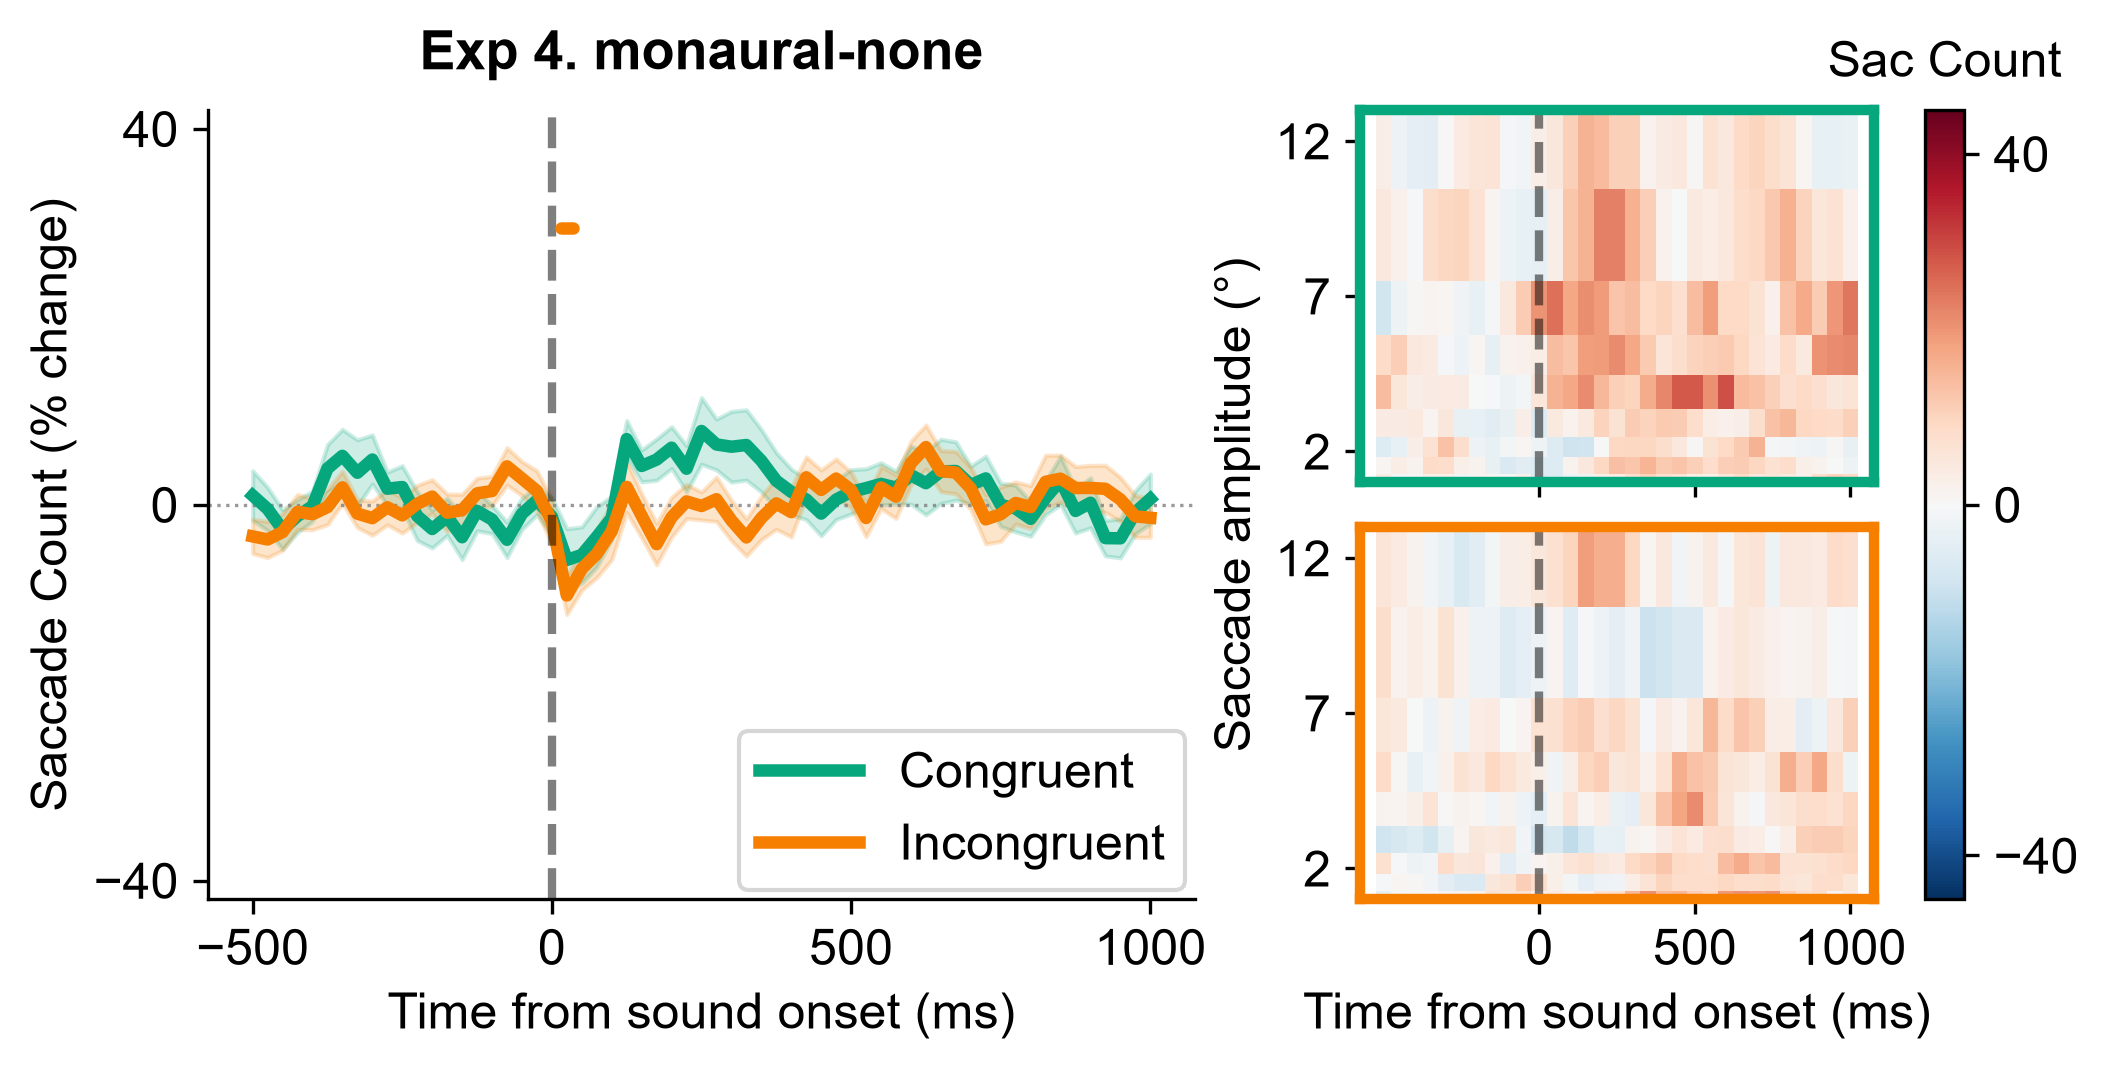

Done.


In [6]:
colors          = COLOR_PALETTES[2]   # [congruent_color, incongruent_color]
condition_names = ('Congruent', 'Incongruent')
conditions_list = ['consistent', 'inconsistent']
hm_ylabel       = f'Saccade amplitude ({HM_AMPLITUDE_UNIT})'

# Draw into the top-left cell of a canvas laid out exactly like Figure 2's 2x2 grid, so the
# axes, gaps and therefore the text-to-plot proportions are identical to one Fig 2 panel.
# bbox_inches='tight' then crops away the three empty cells. (A standalone CELL_W_V2 x
# CELL_H_V2 canvas would give axes 12.5 % wider and 20 % taller than a Fig 2 panel, so once
# shrunk to panel size all text would come out smaller.)
fig = plt.figure(figsize=(CELL_W_V2 * 2, CELL_H_V2 * 2))

outer_gs = gridspec.GridSpec(
    2, 2,
    figure  = fig,
    hspace  = 0.40,
    wspace  = 0.25,
)

# Level 1: [plots | colorbar]
panel_gs = gridspec.GridSpecFromSubplotSpec(
    1, 2,
    subplot_spec = outer_gs[0, 0],
    width_ratios = [LINE_W_RATIO + HM_W_RATIO, CBAR_W_RATIO],
    wspace       = 0.06,
)

# Level 2: [line | heatmaps]
plots_gs = gridspec.GridSpecFromSubplotSpec(
    2, 2,
    subplot_spec  = panel_gs[0, 0],
    width_ratios  = [LINE_W_RATIO, HM_W_RATIO],
    height_ratios = [1, 1],
    wspace        = 0.22,
    hspace        = 0.12,
)

ax_line   = fig.add_subplot(plots_gs[0:2, 0])
ax_hm_top = fig.add_subplot(plots_gs[0, 1])   # no sharex: set_xticks would leak back
ax_hm_bot = fig.add_subplot(plots_gs[1, 1])
ax_cbar   = fig.add_subplot(panel_gs[0, 1])

# ── Line plot ─────────────────────────────────────────────────────────
for ci, res_df in enumerate(results_list):
    plot_single_condition(ax_line, res_df, METRIC, colors[ci], condition_names[ci])

ax_line.axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.5)
# No median-RT line / IQR band: no responses in a no-task experiment.

ax_line.spines['top'].set_visible(False)
ax_line.spines['right'].set_visible(False)
ax_line.grid(False)
ax_line.tick_params(axis='both', labelsize=FONTSIZE, labelbottom=True)
for lbl in ax_line.get_xticklabels() + ax_line.get_yticklabels():
    lbl.set_fontfamily('Arial')
ax_line.set_title(
    EXPERIMENT_LABEL, fontsize=FONTSIZE + 1, fontweight='bold',
    fontfamily='Arial', y=1.02)
ax_line.set_ylabel(
    DEFAULT_METRICS.get(METRIC, {}).get('label', METRIC),
    fontsize=FONTSIZE, fontfamily='Arial')
ax_line.set_xlabel('Time from sound onset (ms)', fontsize=FONTSIZE, fontfamily='Arial')

if LINE_YLIM is not None:
    ax_line.set_ylim(LINE_YLIM)
else:
    ax_line.autoscale_view()

ax_line.axhline(0.0, color='grey', linestyle=':', linewidth=0.8, alpha=0.8, zorder=1)

plot_significance_bars(ax_line, sig[f'{METRIC}_cond0_vs_cond1'], 0.05, 'grey', linewidth=3)
baseline_start = 0.05 + 0.025 + 0.05
for ci in range(2):
    tk = f'{METRIC}_cond{ci}_vs_baseline'
    if tk in sig:
        plot_significance_bars(
            ax_line, sig[tk], baseline_start + ci * 0.025, colors[ci], linewidth=3)

ax_line.set_yticks(_make_3_ticks(*ax_line.get_ylim()))

if PANEL_LABEL:
    ax_line.text(
        -0.2, 1.12, PANEL_LABEL,
        transform=ax_line.transAxes, fontsize=FONTSIZE + 6, fontweight='bold',
        fontfamily='Arial', va='top', ha='left',
    )

legend_handles = [
    Line2D([0], [0], color=colors[0], linewidth=3, label=condition_names[0]),
    Line2D([0], [0], color=colors[1], linewidth=3, label=condition_names[1]),
]
ax_line.legend(
    handles        = legend_handles,
    loc            = LEGEND_LOC,
    bbox_to_anchor = LEGEND_POS,
    prop           = {'family': 'Arial', 'size': FONTSIZE},
    frameon        = True,
)

# ── Heatmaps (from precomputed data) ─────────────────────────────────
for hm_row, (ax_hm, cond_key) in enumerate(zip([ax_hm_top, ax_hm_bot], conditions_list)):
    is_top = (hm_row == 0)

    # Top heatmap: route its unwanted colorbar to a tiny hidden inset
    if is_top:
        _dummy_cax = ax_hm.inset_axes([1.01, 0.0, 0.001, 1.0])
        _cax_arg   = _dummy_cax
    else:
        _cax_arg = ax_cbar

    plot_amplitude_time_heatmap(
        precomputed          = hm_data[cond_key],
        amplitude_unit_label = HM_AMPLITUDE_UNIT,
        median_rt_line       = None,
        ax                   = ax_hm,
        cax                  = _cax_arg,
    )

    if is_top:
        _dummy_cax.set_visible(False)

    for spine in ax_hm.spines.values():
        spine.set_edgecolor(colors[hm_row])
        spine.set_linewidth(HM_SPINE_LW)

    ax_hm.set_ylim(1, 13)
    ax_hm.set_yticks([2, 7, 12])

    ax_hm.set_xlim(ax_line.get_xlim())
    ax_hm.set_xticks([0, 500, 1000])

    show_xlabel = not is_top
    ax_hm.tick_params(axis='both', labelsize=FONTSIZE, labelbottom=show_xlabel)
    for lbl in ax_hm.get_xticklabels() + ax_hm.get_yticklabels():
        lbl.set_fontfamily('Arial')
    ax_hm.xaxis.label.set_fontsize(FONTSIZE)
    ax_hm.xaxis.label.set_fontfamily('Arial')

    ax_hm.set_ylabel('')   # replaced by shared label below
    if show_xlabel:
        ax_hm.set_xlabel('Time from sound onset (ms)', fontsize=FONTSIZE, fontfamily='Arial')
    else:
        ax_hm.set_xlabel('')

# Single y-axis label centred between the two heatmaps
ax_hm_top.text(
    -0.24, -0.06, hm_ylabel,
    transform=ax_hm_top.transAxes, fontsize=FONTSIZE, fontfamily='Arial',
    va='center', ha='center', rotation=90, clip_on=False,
)

ax_cbar.tick_params(labelsize=FONTSIZE)
for lbl in ax_cbar.get_yticklabels():
    lbl.set_fontfamily('Arial')
ax_cbar.title.set_fontfamily('Arial')
ax_cbar.title.set_fontsize(FONTSIZE)

fig.savefig(OUTPUT_PATH / 'figure3.png', dpi=300, bbox_inches='tight')
fig.savefig(OUTPUT_PATH / 'figure3.pdf', bbox_inches='tight')
plt.show()
print('Done.')

## Reported values

The statistics behind Figure 3, as the manuscript quotes them (`src/stats_report.py`): windows
whose FDR-corrected Wilcoxon test is significant, grouped into intervals (window centres), with
direction and mean size. Saccade count is % change, so its baseline is 0 %.

In [7]:
import stats_report as sr
importlib.reload(sr)

report_exp4 = sr.report(
    sig, METRIC, {'consistent': results_consistent, 'inconsistent': results_inconsistent},
    f'{EXPERIMENT_LABEL} - saccade count, sound-locked', step=STEP_SIZE,
    extremes=(('min', (0, 450)), ('max', (50, 450))))


Exp 4. monaural-none - saccade count, sound-locked   [saccade_count_normalized, n = 40]
  congruent vs baseline       none significant (smallest FDR p = 0.080)
  incongruent vs baseline              25 ms  below baseline      mean Δ   -9.7 pp   FDR p = 0.021
  congruent vs incongruent    none significant (smallest FDR p = 0.262)
  congruent   min in 0–450 ms:  t = 25 ms,  -5.9 %
  incongruent min in 0–450 ms:  t = 25 ms,  -9.7 %
  congruent   max in 50–450 ms:  t = 250 ms,  +7.8 %
  incongruent max in 50–450 ms:  t = 425 ms,  +2.9 %
